::: {.sb-lesson-links}
[Exercises →](../exercises/911-emergencies.ipynb)
[Quiz →](../quiz/quiz.qmd)
[All files of this section (zip)](../../files/02-dbscan.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-workflow.ipynb){download="lesson-workflow.ipynb"}
:::

In the previous lesson we chose `eps` and `min_samples` by trial and error. This lesson gives a method: scale the data when needed, choose `min_samples`, read `eps` on a k-distance plot, and pick the right distance, including the distance on the Earth for latitude / longitude data.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

COLORS = ["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3"]
NOISE = "#999999"

def plot_clusters(ax, X, labels, title):
    # Scatter plot with one colour per cluster and the noise (label -1) as grey crosses
    for k in np.unique(labels):
        part = X[labels == k]
        if k == -1:
            ax.scatter(part[:, 0], part[:, 1], s=18, c=NOISE, marker="x", label="noise")
        else:
            ax.scatter(part[:, 0], part[:, 1], s=12, color=COLORS[k % len(COLORS)], label=f"cluster {k}")
    ax.set_title(title, fontsize=11)

def n_clusters(labels):
    # Number of clusters, without the noise label -1
    labels = np.asarray(labels)
    return len(set(labels)) - (1 if -1 in labels else 0)

## The workflow 🗺️

1. **Decide what a cluster means for your problem**, in the units of the data.
2. **Scale** the features if they are not in the same unit.
3. **Choose `min_samples`.**
4. **Choose `eps`** with a k-distance plot, and check that it makes sense.
5. **Choose the distance** (`metric`): Euclidean by default, haversine for latitude / longitude.
6. **Fit and read the results**: number of clusters, share of noise, size and content of each cluster.

## Step 1: what is a cluster for you? Customers in a store 🛒



::: {.callout-tip title="Intuition"}
A store manager records the position of the customers (in metres) at different times of the day. She wants to know where they gather, to change the layout or to put the most popular products in those spots. What is a "gathering"? She decides: **at least 10 customers within 2 m of each other**. This sentence *is* a DBSCAN setting: `min_samples=10`, `eps=2`. Before any formula, the best way to choose the settings is to ask what a cluster means for the problem.
:::



#### See it with data 🔬: where do the customers gather?

We simulate 450 positions in a 30 m × 20 m store: a line of checkouts along the right wall, a promotion stand, the bakery corner, and 150 customers walking around anywhere.

3 clusters, 89 positions labelled noise out of 450
size of each cluster: [146 118  97]


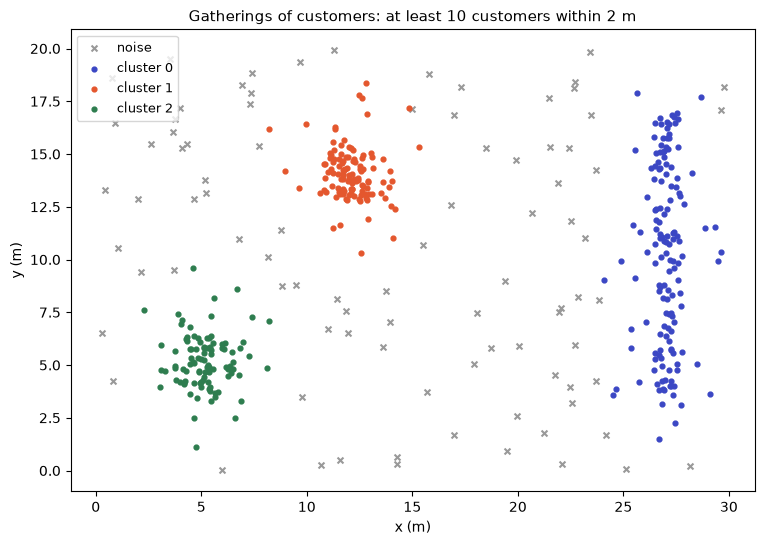

In [ ]:
rng = np.random.default_rng(0)
checkouts = np.c_[rng.normal(27, 0.4, 120), rng.uniform(3, 17, 120)]   # a long queue along the wall
promotion = rng.normal([12, 14], 0.8, size=(100, 2))
bakery = rng.normal([5, 5], 1.0, size=(80, 2))
walking = np.c_[rng.uniform(0, 30, 150), rng.uniform(0, 20, 150)]      # anywhere in the store
store = np.vstack([checkouts, promotion, bakery, walking])             # x and y in metres

store_db = DBSCAN(eps=2, min_samples=10).fit(store)
labels = store_db.labels_
print(f"{n_clusters(labels)} clusters, {(labels == -1).sum()} positions labelled noise out of {len(store)}")
print("size of each cluster:", np.bincount(labels[labels >= 0]))

fig, ax = plt.subplots(figsize=(9, 6))
plot_clusters(ax, store, labels, "Gatherings of customers: at least 10 customers within 2 m")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="upper left", fontsize=9)
plt.show()

**What this shows:** DBSCAN finds the 3 gatherings: the checkouts (146 positions), the promotion stand (118) and the bakery (97). The checkout cluster is a long thin line, a shape K-Means would cut into pieces. 89 positions are noise: mostly the customers walking around, plus a few people at the edge of a gathering. Both coordinates are in metres, so no scaling is needed and `eps=2` means exactly 2 m on the floor.

## Step 2: scale the features when the units differ 📏

`eps` is **one** radius, the same in every direction. If one feature is in years and another in euros, a distance of 2 means "2 years" in one direction and "2 euros" in the other: the feature with the largest numbers decides everything. As for K-Means, standardise the features first (`StandardScaler`), unless they share the same unit (positions in metres, latitude and longitude...).

#### See it with data 🔬: age in years, income in euros

450 customers in 3 groups: young with a low income, older with a low income, older with a high income. We run DBSCAN on the raw values, then on the standardised values.

raw values,  eps=1000: 2 clusters, 13 noise
standardised, eps=0.3: 3 clusters, 2 noise


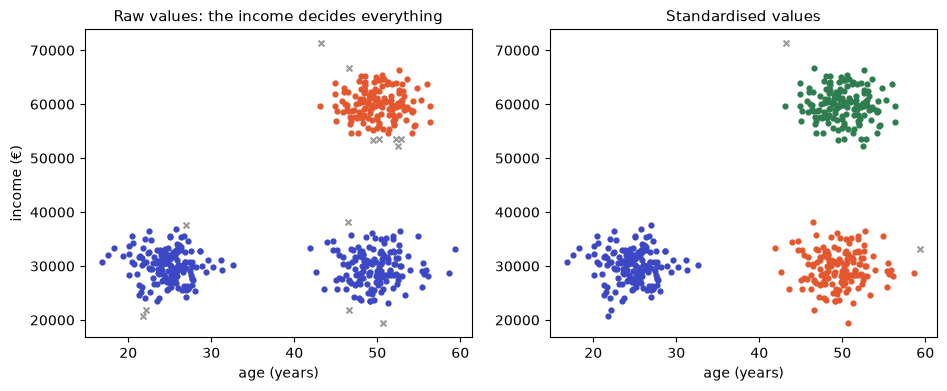

In [ ]:
rng = np.random.default_rng(1)
age = np.r_[rng.normal(25, 3, 150), rng.normal(50, 3, 150), rng.normal(50, 3, 150)]
income = np.r_[rng.normal(30_000, 3_000, 150), rng.normal(30_000, 3_000, 150), rng.normal(60_000, 3_000, 150)]
customers = np.c_[age, income]

raw_labels = DBSCAN(eps=1000, min_samples=8).fit_predict(customers)
scaled = StandardScaler().fit_transform(customers)
scaled_labels = DBSCAN(eps=0.3, min_samples=8).fit_predict(scaled)
print(f"raw values,  eps=1000: {n_clusters(raw_labels)} clusters, {(raw_labels == -1).sum()} noise")
print(f"standardised, eps=0.3: {n_clusters(scaled_labels)} clusters, {(scaled_labels == -1).sum()} noise")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_clusters(axes[0], customers, raw_labels, "Raw values: the income decides everything")
plot_clusters(axes[1], customers, scaled_labels, "Standardised values")
for ax in axes:
    ax.set_xlabel("age (years)")
axes[0].set_ylabel("income (€)")
plt.show()

**What this shows:** on the raw values, a radius of 1,000 is huge for the age (it covers all ages) and small for the income. The two low-income groups, 25 years apart, are merged: 2 clusters instead of 3. Whatever `eps` we try, the age is ignored. After standardisation, both features count equally and DBSCAN finds the 3 groups (3 clusters, only 2 noise points). (The plot on the right shows the original units; the clustering used the standardised ones.)

## Step 3: choose `min_samples` 🔢

There is no formula, only good habits:

* **Use the meaning of the problem** when there is one ("10 customers make a crowd").
* Otherwise, a common starting point is **twice the number of features**: `min_samples = 4` for 2D data. Never go below 3: with `min_samples=2`, any pair of close points becomes a cluster. More generally, use at least the number of features + 1.
* **Increase it when the data is large or noisy**: with 100,000 points, 4 points close together happen by chance everywhere. A larger `min_samples` gives fewer, more solid clusters, and more noise.

## Step 4: choose `eps` with the k-distance plot 📈



::: {.callout-tip title="Intuition"}
For each point, measure the radius of the smallest circle around it that contains `min_samples` points. Inside a cluster this radius is small; for an isolated point it is large. Sort all these radii and plot them: the curve is flat and low for the points in the clusters, then shoots up for the isolated points. The bend of the curve, the **elbow**, is the radius where "inside a cluster" turns into "isolated": a good candidate for `eps`.
:::



In practice: with `k = min_samples`, compute for every point the distance to its k-th nearest neighbour (the point itself counts as the first one, exactly like in DBSCAN), sort these distances and plot them. A point is a core point **exactly** when this distance is $\le$ `eps`. So the curve also tells, for any `eps`, how many points will be core points.

#### See it with data 🔬: the k-distance plot of the store

We use `min_samples=10`, so `k=10`. `NearestNeighbors(n_neighbors=10)` returns, for every point, the distances to its 10 nearest points, the point itself first (distance 0). The last column is the radius we want.

In [ ]:
k = 10
distances, _ = NearestNeighbors(n_neighbors=k).fit(store).kneighbors(store)
k_distance = np.sort(distances[:, -1])                    # distance to the 10th point, itself included

fig = go.Figure(go.Scatter(y=k_distance, mode="lines", name="k-distance"))
fig.add_hline(y=2, line_dash="dash", annotation_text="eps = 2 m (the manager's choice)")
fig.update_layout(title="k-distance plot of the store (k = 10), sorted",
                  xaxis_title="positions, sorted by their k-distance", yaxis_title="distance to the 10th point (m)")
fig.show()

for e in [1, 2, 3]:
    model = DBSCAN(eps=e, min_samples=k).fit(store)
    print(f"eps = {e} m: {(k_distance <= e).sum()} points with a k-distance <= eps, "
          f"{len(model.core_sample_indices_)} core points for DBSCAN -> "
          f"{n_clusters(model.labels_)} clusters, {(model.labels_ == -1).sum()} noise")

eps = 1 m: 282 points with a k-distance <= eps, 282 core points for DBSCAN -> 3 clusters, 130 noise
eps = 2 m: 336 points with a k-distance <= eps, 336 core points for DBSCAN -> 3 clusters, 89 noise
eps = 3 m: 374 points with a k-distance <= eps, 374 core points for DBSCAN -> 2 clusters, 34 noise


**What this shows:** the curve stays low and flat for about 290 positions, then bends upwards around 1 m. Below the bend are the positions inside a gathering, above it the customers walking alone. The printed lines check the property: for every `eps`, the number of points with a k-distance $\le$ `eps` is exactly the number of core points found by DBSCAN (282 for 1 m, 336 for 2 m).

The elbow (1 m) and the manager's choice (2 m) both give the same 3 gatherings: 1 m keeps only their dense heart (130 noise points), 2 m also takes their edges (89 noise points). With 3 m, the radius is too generous: the promotion stand and the bakery are joined through the customers walking between them, and only 2 clusters are left.

The elbow is a guide, not a law. On real data the bend is often soft. Read a range of candidates on the curve, try two or three of them, and keep the one whose clusters make sense for the problem.

## Step 5: choose the distance (`metric`) 📐

DBSCAN only needs distances, so any distance works. The neighbourhood is the set of points at a distance $\le$ `eps`, and its shape depends on the distance:

* **Euclidean** (default), $\sqrt{(x_1-y_1)^2 + (x_2-y_2)^2}$: the straight line. The neighbourhood is a disc.
* **Manhattan**, $|x_1-y_1| + |x_2-y_2|$: the distance along the streets of a grid city. The neighbourhood is a diamond, a bit smaller than the disc.
* **Haversine**: the distance on the surface of the Earth, for latitude / longitude (below).
* `metric="precomputed"`: you give DBSCAN your own table of distances (a travel time, a text similarity...).

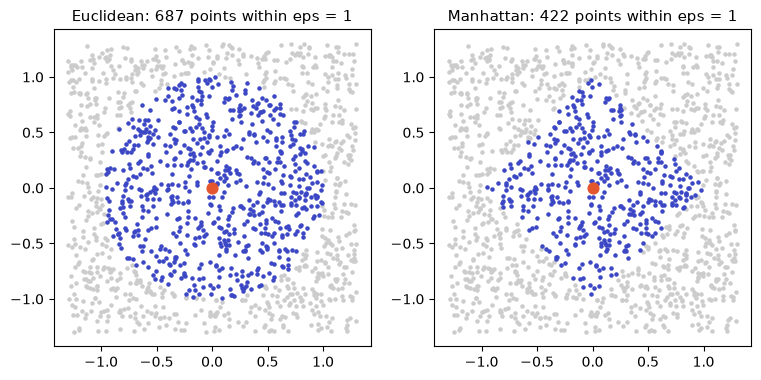

In [ ]:
rng = np.random.default_rng(2)
cloud = rng.uniform(-1.3, 1.3, size=(1500, 2))
euclidean = np.sqrt((cloud ** 2).sum(axis=1))
manhattan = np.abs(cloud).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, dist, name in [(axes[0], euclidean, "Euclidean"), (axes[1], manhattan, "Manhattan")]:
    inside = dist <= 1
    ax.scatter(*cloud[~inside].T, s=5, color="#CCCCCC")
    ax.scatter(*cloud[inside].T, s=5, color=COLORS[0])
    ax.scatter(0, 0, s=60, color=COLORS[1], zorder=3)
    ax.set_title(f"{name}: {inside.sum()} points within eps = 1", fontsize=11)
    ax.set_aspect("equal")
plt.show()

**What this shows:** with the same `eps = 1`, the Euclidean neighbourhood is a disc and the Manhattan one is a diamond, with fewer points inside (422 points against 687). If you switch from one distance to the other, `eps` must change too. On most data, the Euclidean distance is the natural choice; the Manhattan distance makes sense when moves are along a grid.

### Latitude and longitude: the haversine distance 🌍

Latitude and longitude are **angles**, not distances. One degree of latitude is always about 111 km, but one degree of longitude shrinks towards the poles: about 85 km at the latitude of Philadelphia, 73 km in Paris. A Euclidean distance on degrees therefore stretches the map in one direction.

![A cell of 0.01 degree by 0.01 degree is a square in degrees, but a rectangle of 1112 m by 852 m on the ground at latitude 40 degrees north](../img/dbscan_degrees_vs_metres.png)

The **haversine** formula gives the distance along the surface of a sphere of radius $R$ (6,371 km for the Earth), for two points of latitude $\varphi_1, \varphi_2$ and longitude $\lambda_1, \lambda_2$ in radians:

$$d = 2R\,\arcsin\sqrt{\sin^2\!\left(\frac{\varphi_2-\varphi_1}{2}\right) + \cos\varphi_1\cos\varphi_2\,\sin^2\!\left(\frac{\lambda_2-\lambda_1}{2}\right)}$$

Scikit-learn's haversine works on a sphere of radius 1, with `[latitude, longitude]` **in radians**, in this order. It returns an angle: multiply by 6,371 to get kilometres. And to ask DBSCAN for a radius of 300 m, divide: `eps = 0.3 / 6371`.

#### See it with data 🔬: from the Eiffel Tower to the Louvre, by hand

We compute the distance between the Eiffel Tower and the Louvre pyramid with the formula, with scikit-learn, and with the (wrong) Euclidean distance on degrees.

In [ ]:
places = pd.DataFrame({"lat": [48.8584, 48.8611], "lng": [2.2945, 2.3358]}, index=["Eiffel Tower", "Louvre"])
R = 6371                                                  # radius of the Earth, km
phi1, lam1, phi2, lam2 = np.radians(places.to_numpy().ravel())

by_hand = 2 * R * np.arcsin(np.sqrt(np.sin((phi2 - phi1) / 2) ** 2
                                    + np.cos(phi1) * np.cos(phi2) * np.sin((lam2 - lam1) / 2) ** 2))
with_sklearn = haversine_distances(np.radians(places.to_numpy()))[0, 1] * R
degrees = np.sqrt(((places.iloc[0] - places.iloc[1]) ** 2).sum())   # Euclidean distance on degrees

print(f"haversine by hand      : {by_hand:.3f} km")
print(f"haversine_distances x R: {with_sklearn:.3f} km")
print(f"Euclidean on degrees   : {degrees:.4f} 'degrees', i.e. {degrees * 111.2:.3f} km if we take 1° = 111.2 km")

haversine by hand      : 3.036 km
haversine_distances x R: 3.036 km
Euclidean on degrees   : 0.0414 'degrees', i.e. 4.602 km if we take 1° = 111.2 km


**What this shows:** the formula and scikit-learn agree: 3.036 km between the two monuments. The Euclidean distance on degrees, converted with 111.2 km per degree, gives 4.602 km: about 50% too much, because a degree of longitude is only about 73 km in Paris. The error depends on the direction (none north–south, the largest east–west), so a Euclidean `eps` on degrees is not a circle on the ground.

#### See it with data 🔬: photo hot spots in Paris

We simulate the GPS positions of 400 holiday photos: 100 around each of three monuments (within about 100 m), and 100 taken anywhere in the centre of Paris. We look for spots with **at least 15 photos within 150 m**.

In [ ]:
rng = np.random.default_rng(3)
spots = {"Eiffel Tower": (48.8584, 2.2945), "Louvre": (48.8611, 2.3358), "Notre-Dame": (48.8530, 2.3499)}
rows = []
for name, (lat, lng) in spots.items():
    north, east = rng.normal(0, 60, 100), rng.normal(0, 60, 100)          # offsets in metres
    rows.append(pd.DataFrame({"lat": lat + north / 111_200,
                              "lng": lng + east / (111_200 * np.cos(np.radians(lat)))}))
rows.append(pd.DataFrame({"lat": rng.uniform(48.84, 48.88, 100), "lng": rng.uniform(2.28, 2.37, 100)}))
photos = pd.concat(rows, ignore_index=True)

eps_m = 150
photo_db = DBSCAN(eps=eps_m / 6_371_000, min_samples=15, metric="haversine", algorithm="ball_tree")
photos["cluster"] = photo_db.fit_predict(np.radians(photos[["lat", "lng"]]))
print(f"{n_clusters(photos.cluster)} hot spots, {(photos.cluster == -1).sum()} photos labelled noise")
photos.groupby("cluster").agg(photos=("lat", "size"), lat=("lat", "mean"), lng=("lng", "mean")).round(4)

3 hot spots, 95 photos labelled noise


,photos,lat,lng
cluster,,,
-1,95,48.8583,2.3265
0,102,48.8584,2.2946
1,102,48.8611,2.3358
2,101,48.8531,2.3500


In [ ]:
fig = px.scatter_map(photos.assign(group=photos.cluster.astype(str).replace("-1", "noise")),
                     lat="lat", lon="lng", color="group", zoom=12.5, height=450,
                     map_style="carto-positron", title="Photo hot spots found with the haversine distance")
fig.show()

**What this shows:** DBSCAN finds the 3 hot spots. The table gives their centres, right on the three monuments, and the size of each one (100 photos or a little more: a few random photos fall inside a spot). 95 photos are noise: almost all the photos taken elsewhere. Thanks to the haversine distance, `eps` is a real radius on the ground, 150 m, whatever the direction.

## The `algorithm` parameter (optional) ⚙️

To find the neighbours of every point, scikit-learn can compare all the pairs of points (`algorithm="brute"`), or first organise the points in a tree that makes the search faster (`"kd_tree"` or `"ball_tree"`). The default, `"auto"`, picks one for you. This choice changes the speed and the memory used, **never the result**. Two practical notes:

* the haversine distance works with `"ball_tree"` or `"brute"`, not with `"kd_tree"`;
* DBSCAN stores the neighbourhood of every point: with a large `eps` on a large dataset, it can run out of memory. Reduce `eps`, or remove duplicate points and pass their counts with `sample_weight`.

In [ ]:
reference = DBSCAN(eps=2, min_samples=10).fit_predict(store)
for algorithm in ["brute", "kd_tree", "ball_tree"]:
    labels = DBSCAN(eps=2, min_samples=10, algorithm=algorithm).fit_predict(store)
    print(f"{algorithm:<9}: same labels as 'auto' -> {(labels == reference).all()}")

brute    : same labels as 'auto' -> True
kd_tree  : same labels as 'auto' -> True
ball_tree: same labels as 'auto' -> True


## Step 6: fit and read the results 🔎

After `fit`, the model gives:

* `labels_`: the cluster of each point, -1 for noise. `fit_predict(X)` returns the same array in one step.
* `core_sample_indices_`: the positions of the core points; `components_`: their coordinates.

Count the clusters with `len(set(labels)) - (1 if -1 in labels else 0)`, and always look at the **share of noise**: 5% and 60% of noise tell two very different stories. Then describe each cluster with the original columns, with a `groupby`:

In [ ]:
summary = (pd.DataFrame(store, columns=["x", "y"])
           .assign(cluster=store_db.labels_, core=False))
summary.loc[store_db.core_sample_indices_, "core"] = True
summary.groupby("cluster").agg(positions=("x", "size"), core_points=("core", "sum"),
                               x_centre=("x", "mean"), y_centre=("y", "mean"),
                               width=("x", lambda v: v.max() - v.min()), height=("y", lambda v: v.max() - v.min())).round(1)

,positions,core_points,x_centre,y_centre,width,height
cluster,,,,,,
-1,89,0,14.2,10.5,29.5,19.9
0,146,135,27.0,10.2,5.6,16.4
1,118,109,12.1,14.1,7.1,8.1
2,97,92,5.2,5.2,5.9,8.5


**What this shows:** cluster 0 (the checkouts) is long and thin: 16.4 m long and 5.6 m wide, border points included, with 135 core points out of 146 positions. The noise row (-1) has no core points, as expected. A cluster is a set of rows of your data: once you have the labels, every pandas tool applies.

## Summary ✅

* Start from the meaning: "how many points, within which distance, make a group?" gives `min_samples` and `eps` in the units of the data.
* Scale the features when their units differ; don't when they are coordinates in the same unit.
* `min_samples`: about twice the number of features by default, more for large or noisy data.
* `eps`: read candidates at the elbow of the k-distance plot (`k = min_samples`), then check the clusters.
* Latitude / longitude: `metric="haversine"`, coordinates in radians (`np.radians`), `eps = metres / 6,371,000`.
* Look at the number of clusters, the share of noise, and describe each cluster with a `groupby`.

## Resources 📚

* [`DBSCAN` in the scikit-learn API reference](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
* [Nearest neighbour algorithms (brute force, k-d tree, ball tree)](https://scikit-learn.org/stable/modules/neighbors.html#nearest-neighbor-algorithms)
* [Haversine formula on Wikipedia](https://en.wikipedia.org/wiki/Haversine_formula)

::: {.sb-next}
**[Your turn: DBSCAN exercises →](../exercises/911-emergencies.ipynb)**
:::